In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("netflix_titles.csv")
df["rating_group"] = df["rating"].map(groups)          # the groups dict from before
df = df.dropna(subset=["rating_group", "description"]) # drops missing, invalid, NR/UR
df = df.drop_duplicates(subset="description")          
print(df.shape)        


(8807, 12)


In [10]:
print(df.head())


  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [11]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB
None


In [12]:
print(df.isnull().sum())     

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


In [13]:
print(df.duplicated().sum())  


0


In [14]:
print(df["rating"].value_counts())        

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


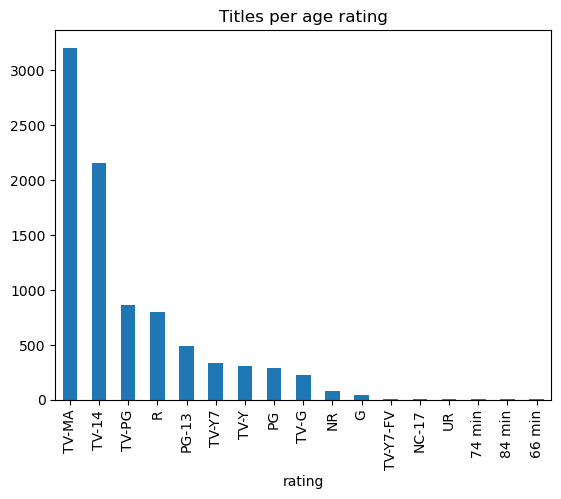

In [4]:
df["rating"].value_counts().plot(kind="bar")
plt.title("Titles per age rating")
plt.show()

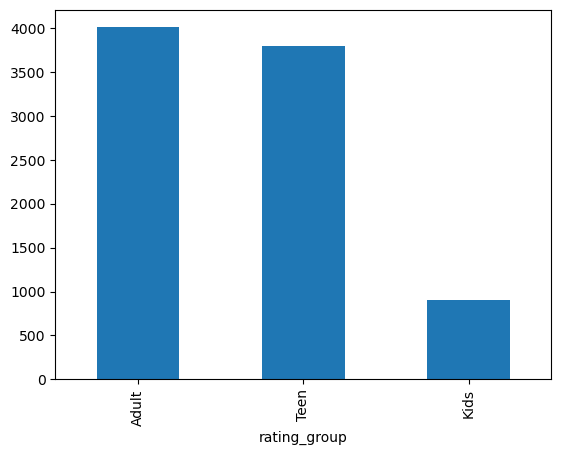

In [5]:
groups = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "PG": "Teen", "TV-PG": "Teen", "PG-13": "Teen", "TV-14": "Teen",
    "R": "Adult", "TV-MA": "Adult", "NC-17": "Adult",
}
df["rating_group"] = df["rating"].map(groups)
df = df.dropna(subset=["rating_group"])
df["rating_group"].value_counts().plot(kind="bar")
plt.show()

count    8717.000000
mean       23.887002
std         2.841453
min        10.000000
25%        22.000000
50%        24.000000
75%        26.000000
max        48.000000
Name: desc_len, dtype: float64


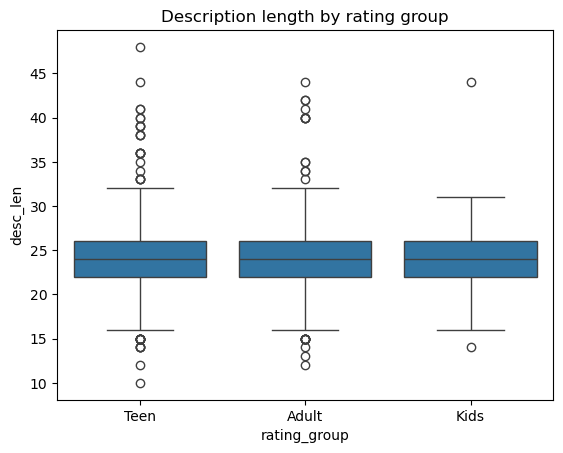

In [6]:
df["desc_len"] = df["description"].str.split().str.len()
print(df["desc_len"].describe())

sns.boxplot(data=df, x="rating_group", y="desc_len")
plt.title("Description length by rating group")
plt.show()

In [7]:
from sklearn.feature_extraction.text import CountVectorizer

for g in ["Kids", "Teen", "Adult"]:
    text = df.loc[df["rating_group"] == g, "description"]
    cv = CountVectorizer(stop_words="english")
    counts = cv.fit_transform(text).sum(axis=0).A1
    top = pd.Series(counts, index=cv.get_feature_names_out()).nlargest(15)
    print(g, list(top.index))

Kids ['friends', 'new', 'world', 'save', 'help', 'series', 'adventures', 'evil', 'family', 'fun', 'young', 'adventure', 'home', 'life', 'best']
Teen ['life', 'young', 'love', 'new', 'family', 'world', 'man', 'woman', 'documentary', 'father', 'school', 'finds', 'series', 'old', 'high']
Adult ['life', 'young', 'new', 'family', 'man', 'woman', 'world', 'love', 'series', 'documentary', 'friends', 'group', 'takes', 'stand', 'murder']


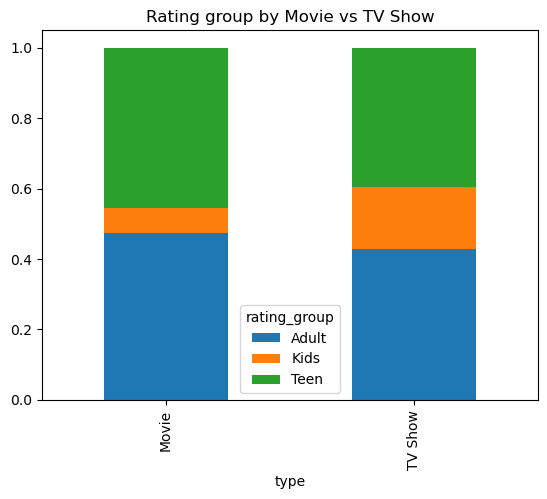

In [8]:
pd.crosstab(df["type"], df["rating_group"], normalize="index").plot(kind="bar", stacked=True)
plt.title("Rating group by Movie vs TV Show")
plt.show()